# NB 06 · Scénario final : Corrélation et bulletin de renseignement

**Situation :** la chaîne est complète. Spirit Digger sait évaluer ses sources (NB 00), ingérer (01), inventorier (02), détecter (03), relier (04) et décrypter les narratifs (05). Il reste l'essentiel : **produire un livrable que l'état-major lit en deux minutes**, et **déclencher l'action**.

**Le livrable : un bulletin de renseignement** généré automatiquement pour une période donnée.
1. **BLUF** (*Bottom Line Up Front*) : l'essentiel en trois lignes, en tête, selon le format militaire.
2. **Événement principal**, avec sa **cotation OTAN** (code de l'Amirauté), sa chronologie, ses sources par camp et des extraits.
3. **Guerre de l'information** : les récits opposés.
4. **Autres signaux** de la période, chacun coté.
5. **Demande d'observation satellite** adressée à **God's Eye**, pour confirmer visuellement.

**Le parallèle avec God's Eye :** son scénario 4 croisait une intrusion (T1) et des destructions (T2) pour conclure « attaque confirmée ». Ici, on croise **des sources textuelles de camps opposés**, puis on passe la main à l'imagerie. **Le texte détecte, l'image confirme.**

In [1]:
import sys
from pathlib import Path

# On retrouve la racine du projet (le dossier qui contient data_lake/) pour importer src/
RACINE = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "data_lake").is_dir())
sys.path.insert(0, str(RACINE / "src"))

import base64
import io
import json
from html import escape

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import HTML, display

from spirit_digger.analyse_ru import (MARQUEURS, mots_de_combat, presence, racines, retirer_pieds, traduire)
from spirit_digger.config import OUTPUTS
from spirit_digger.style import ACCENT, ALERTE, FOND, OK, TEXTE, VEILLE, bandeau, theme_ops

theme_ops()
pd.set_option("display.max_colwidth", 100)
bandeau("NB 06 · Corrélation et bulletin", "Du signal au renseignement coté, puis à l'action.")

alertes = pd.read_csv(OUTPUTS / "alertes_ukraine.csv", parse_dates=["jour"])
alertes["racines"] = alertes["racines"].str.split(", ")
telegram = pd.read_parquet(OUTPUTS / "corpus_ukraine.parquet", columns=["date", "source", "camp", "texte"])
telegram["texte"] = retirer_pieds(telegram)           # pieds de message retirés (méthode du NB 05)
telegram["jour"] = telegram["date"].dt.normalize()
PAR_JOUR = dict(tuple(telegram.groupby("jour")))
FOND_LEXICAL = presence(telegram["texte"].sample(60_000, random_state=1))
print(f"{len(alertes)} alertes du NB 03 · {len(telegram):,} messages")

210 alertes du NB 03 · 382,217 messages


## 1. La cotation OTAN : le code de l'Amirauté

Chaque information reçoit **deux notes indépendantes** (doctrine OTAN, STANAG 2511 / AJP-2.1) :

| Fiabilité de la **source** | | Crédibilité de l'**information** | |
|---|---|---|---|
| **A** | complètement fiable | **1** | confirmée par d'autres sources indépendantes |
| **B** | habituellement fiable | **2** | probablement vraie |
| **C** | assez fiable | **3** | possiblement vraie |
| **D** | habituellement peu fiable | **4** | douteuse |
| **E** | peu fiable | **5** | improbable |
| **F** | ne peut être jugée | **6** | ne peut être jugée |

« B2 » se lit donc : *source habituellement fiable, information probablement vraie*. Un renseignement « D1 » (source peu fiable, mais info confirmée par ailleurs) vaut **plus** qu'un « A4 ».

### 1.1 Fiabilité des sources (lettre) : cotation *a priori*

C'est un **jugement d'analyste**, documenté et modifiable. On cote les camps, pas les journalistes.

In [2]:
FIABILITE = {
    "International": ("B", "rédactions indépendantes, standards de vérification publiés"),
    "Russe indépendant (exil)": ("B", "rédactions indépendantes, mais à distance du terrain"),
    "Ukraine": ("C", "médias d'un belligérant, sous loi martiale"),
    "Russie - presse sous contrainte": ("C", "presse privée soumise à la censure militaire"),
    "Russie - État": ("D", "organes d'État d'un belligérant, régulièrement épinglés pour désinformation"),
}
pd.DataFrame([(camp, lettre, raison) for camp, (lettre, raison) in FIABILITE.items()],
             columns=["camp", "fiabilité", "justification"]).style.hide(axis="index")

camp,fiabilité,justification
International,B,"rédactions indépendantes, standards de vérification publiés"
Russe indépendant (exil),B,"rédactions indépendantes, mais à distance du terrain"
Ukraine,C,"médias d'un belligérant, sous loi martiale"
Russie - presse sous contrainte,C,presse privée soumise à la censure militaire
Russie - État,D,"organes d'État d'un belligérant, régulièrement épinglés pour désinformation"


### 1.2 Crédibilité de l'information (chiffre) : calcul automatique par recoupement

Ici, la machine peut aider **objectivement** : on compte **combien de camps** rapportent l'information le jour de l'alerte ou le lendemain. Un camp ne « confirme » que s'il y consacre **au moins 2 % de ses messages, et au moins 5 messages** : une mention en passant ne compte pas. **Le point clé** est le recoupement entre **belligérants opposés** : quand la Russie *et* l'Ukraine disent qu'un fait a eu lieu (même en s'accusant mutuellement), le fait est quasi certain.

| Chiffre | Règle |
|---|---|
| **1** | les deux belligérants **et** au moins un camp neutre |
| **2** | les deux belligérants, ou au moins 3 camps |
| **3** | 2 camps |
| **4** | 1 seul camp |
| **6** | pas assez de messages |

Le chiffre **5** (improbable) suppose qu'une source *contredise* l'information. Ce jugement reste réservé à l'analyste.

In [3]:
RUSSIE = {"Russie - État", "Russie - presse sous contrainte"}
UKRAINE = {"Ukraine"}
NEUTRES = {"International", "Russe indépendant (exil)"}
ORDRE_FIAB = "ABCDEF"


def corroborer(jour, mots, min_messages=5, min_part=0.02):
    """Messages du jour et du lendemain contenant une racine de l'alerte, et camps qui confirment."""
    tous = pd.concat([PAR_JOUR.get(jour, pd.DataFrame()), PAR_JOUR.get(jour + pd.Timedelta(days=1), pd.DataFrame())])
    cles = set(mots)
    msgs = tous[tous["texte"].map(lambda t: bool(racines(t) & cles))]
    par_camp = msgs.groupby("camp").agg(messages=("texte", "size"), chaines=("source", lambda s: ", ".join(sorted(set(s)))))
    par_camp["part"] = par_camp["messages"] / tous.groupby("camp").size().reindex(par_camp.index)
    return msgs, par_camp[(par_camp["messages"] >= min_messages) & (par_camp["part"] >= min_part)]


def coter(par_camp):
    camps = set(par_camp.index)
    deux_bords = bool(camps & RUSSIE) and bool(camps & UKRAINE)
    if not camps:
        chiffre = 6
    elif deux_bords and camps & NEUTRES:
        chiffre = 1
    elif deux_bords or len(camps) >= 3:
        chiffre = 2
    else:
        chiffre = 3 if len(camps) == 2 else 4
    lettre = min((FIABILITE[c][0] for c in camps), key=ORDRE_FIAB.index) if camps else "F"
    return f"{lettre}{chiffre}"


cotes = []
for a in alertes.itertuples():
    _, par_camp = corroborer(a.jour, a.racines[:1])
    cotes.append(coter(par_camp))
alertes["cotation"] = cotes
alertes["crédibilité"] = alertes["cotation"].str[1].astype(int)
print("Répartition des cotations sur les", len(alertes), "alertes :")
alertes["cotation"].value_counts().sort_index().rename("alertes").to_frame().T

Répartition des cotations sur les 210 alertes :


cotation,B1,B2,B3,B4,C2,C3,C4,D4,F6
alertes,128,43,10,4,5,11,3,4,2


In [4]:
validation = pd.read_csv(OUTPUTS / "validation_alertes.csv", parse_dates=["date"])
verif = validation.merge(alertes[["jour", "cotation"]], left_on="date", right_on="jour", how="left")
print("Événements de référence (NB 03) et cotation obtenue le jour même :")
verif[["date", "événement", "niveau atteint", "cotation"]].fillna({"cotation": "pas d'alerte ce jour"}) \
    .style.format({"date": lambda d: f"{d:%d/%m/%Y}"}).hide(axis="index")

Événements de référence (NB 03) et cotation obtenue le jour même :


date,événement,niveau atteint,cotation
04/04/2022,Massacre de Boutcha révélé,-,pas d'alerte ce jour
08/04/2022,Frappe sur la gare de Kramatorsk,ALERTE MAXIMALE,B1
14/04/2022,Naufrage du croiseur Moskva,ALERTE MAXIMALE,B1
27/06/2022,Frappe sur le centre commercial de Krementchouk,ALERTE MAXIMALE,B2
14/07/2022,Frappe sur Vinnytsia,ALERTE MAXIMALE,B2
29/07/2022,Explosion à la prison d'Olenivka,ALERTE MAXIMALE,B1
09/08/2022,Explosions sur la base aérienne de Saky (Crimée),ALERTE MAXIMALE,B1
21/08/2022,Assassinat de Daria Douguina,ALERTE,B1
21/09/2022,Mobilisation partielle en Russie,ALERTE MAXIMALE,B1
27/09/2022,Sabotage des gazoducs Nord Stream,VEILLE,B1


**Lecture :** les grands événements vérifiés obtiennent presque tous un **« B1 »** : une source fiable est présente, et l'information est confirmée par les deux belligérants et par un camp neutre. Les alertes cotées **3 ou 4** sont portées par un ou deux camps seulement : ce sont celles qu'un analyste doit **revérifier** avant de les transmettre.

## 2. La passerelle vers God's Eye : demande d'observation satellite

Quand l'événement est **localisable**, Spirit Digger émet une **demande d'observation** (*tasking*) au format JSON, directement exploitable par le pipeline God's Eye :
- les **coordonnées** du site ;
- deux **dates d'acquisition** : T0 avant l'événement, T1 après ;
- le **scénario God's Eye** à appliquer (évaluation des sinistres, violation de périmètre…) ;
- les **classes YOLO** à surveiller, parmi les 22 classes du modèle DOTA + xView.

Le **répertoire des sites** fait le lien entre une racine de mot et un lieu.

In [5]:
SITES = {
    "каховс": {"site": "Barrage et centrale hydroélectrique de Kakhovka", "lat": 46.7781, "lon": 33.3700, "rayon_km": 5,
               "scenario": "Scénario 2 · Évaluation des sinistres",
               "classes": ["bridge", "building", "infrastructure-diverse", "harbor"],
               "question": "Confirmer la rupture du barrage et mesurer l'étendue des destructions en aval."},
    "крымск": {"site": "Pont de Crimée (détroit de Kertch)", "lat": 45.3080, "lon": 36.5090, "rayon_km": 8,
               "scenario": "Scénario 2 · Évaluation des sinistres",
               "classes": ["bridge", "railway-vehicle", "large-vehicle", "ship"],
               "question": "Évaluer les dégâts sur les travées routière et ferroviaire."},
    "ростов": {"site": "Rostov-sur-le-Don, QG du district militaire Sud", "lat": 47.2220, "lon": 39.7100, "rayon_km": 3,
               "scenario": "Scénario 3 · Violation de périmètre",
               "classes": ["large-vehicle", "small-vehicle", "engineering-vehicle", "helicopter"],
               "question": "Détecter la présence de véhicules blindés autour du quartier général."},
    "вагнер": {"site": "Rostov-sur-le-Don, QG du district militaire Sud", "lat": 47.2220, "lon": 39.7100, "rayon_km": 3,
               "scenario": "Scénario 3 · Violation de périmètre",
               "classes": ["large-vehicle", "small-vehicle", "engineering-vehicle", "helicopter"],
               "question": "Détecter la présence de véhicules blindés autour du quartier général."},
    "новофе": {"site": "Base aérienne de Saky (Novofedorivka, Crimée)", "lat": 45.0930, "lon": 33.5950, "rayon_km": 4,
               "scenario": "Scénario 2 · Évaluation des sinistres",
               "classes": ["plane", "building", "storage-tank"],
               "question": "Compter les aéronefs détruits sur les aires de stationnement."},
}


def demande_observation(alerte, cotation):
    site = next((SITES[r] for r in alerte.racines if r in SITES), None)
    if site is None:
        return None
    return {
        "emetteur": "SPIRIT DIGGER v1.0",
        "destinataire": "GOD'S EYE v2.0",
        "reference": f"SD-{alerte.jour:%Y%m%d}-" + "".join(ch for ch in traduire(alerte.racines[0]) if ch.isalnum()),
        "priorite": "IMMÉDIATE" if alerte.niveau == "ALERTE MAXIMALE" else "PRIORITAIRE",
        "cotation_source_texte": cotation,
        "site": site["site"],
        "zone": {"lat": site["lat"], "lon": site["lon"], "rayon_km": site["rayon_km"]},
        "acquisitions": {"T0_reference": f"{alerte.jour - pd.Timedelta(days=7):%Y-%m-%d}",
                         "T1_post_evenement": f"{alerte.jour + pd.Timedelta(days=1):%Y-%m-%d}"},
        "scenario_gods_eye": site["scenario"],
        "classes_yolo_a_surveiller": site["classes"],
        "question": site["question"],
        "indices_textuels": [f"{r} ({traduire(r)})" for r in alerte.racines[:4]],
    }


kakhovka = alertes.loc[alertes["jour"] == "2023-06-06"].iloc[0]
print(json.dumps(demande_observation(kakhovka, kakhovka.cotation), ensure_ascii=False, indent=2))

{
  "emetteur": "SPIRIT DIGGER v1.0",
  "destinataire": "GOD'S EYE v2.0",
  "reference": "SD-20230606-Kakhovka",
  "priorite": "IMMÉDIATE",
  "cotation_source_texte": "B1",
  "site": "Barrage et centrale hydroélectrique de Kakhovka",
  "zone": {
    "lat": 46.7781,
    "lon": 33.37,
    "rayon_km": 5
  },
  "acquisitions": {
    "T0_reference": "2023-05-30",
    "T1_post_evenement": "2023-06-07"
  },
  "scenario_gods_eye": "Scénario 2 · Évaluation des sinistres",
  "classes_yolo_a_surveiller": [
    "bridge",
    "building",
    "infrastructure-diverse",
    "harbor"
  ],
  "question": "Confirmer la rupture du barrage et mesurer l'étendue des destructions en aval.",
  "indices_textuels": [
    "каховс (Kakhovka)",
    "каховк (Kakhovka)",
    "затопл (inondation)",
    "плотин (barrage)"
  ]
}


> **Le monde réel a suivi exactement ce chemin.** Le message représentatif de l'alerte du 06/06 (voir NB 03) relaie la publication par UNIAN d'**images satellite Planet Labs** du barrage détruit. Le texte a détecté l'événement, et l'imagerie l'a confirmé.

## 3. Le générateur de bulletin

Une seule fonction : `generer_bulletin(debut, fin)`. Elle prend l'alerte la plus forte de la période comme événement principal et assemble tout le reste. Le bulletin est un fichier **HTML autonome et imprimable** : les graphiques y sont intégrés, aucune connexion n'est nécessaire.

In [6]:
ORDRE_CAMPS = ["Russie - État", "Russie - presse sous contrainte", "Russe indépendant (exil)", "International", "Ukraine"]
COURT = {"Russie - État": "Russie (État)", "Russie - presse sous contrainte": "Russie (sous contrainte)",
         "Russe indépendant (exil)": "Russe (exil)", "International": "International", "Ukraine": "Ukraine"}
COULEUR_CAMP = {"Russie - État": "#d64550", "Russie - presse sous contrainte": "#e8a0a5",
                "Russe indépendant (exil)": "#7c5cff", "International": "#4c9be8", "Ukraine": "#f2c230"}


def figure_png(fig):
    tampon = io.BytesIO()
    fig.savefig(tampon, format="png", dpi=110, bbox_inches="tight", facecolor="white")
    plt.close(fig)
    return "data:image/png;base64," + base64.b64encode(tampon.getvalue()).decode()


def chronologie(alerte):
    """Messages par jour et par camp contenant la racine principale, de J-7 à J+7."""
    jours = pd.date_range(alerte.jour - pd.Timedelta(days=7), alerte.jour + pd.Timedelta(days=7))
    lignes = []
    for j in jours:
        msgs = PAR_JOUR.get(j)
        if msgs is not None:
            m = msgs[msgs["texte"].map(lambda t: alerte.racines[0] in racines(t))]
            lignes += [{"jour": j, "camp": c} for c in m["camp"]]
    table = pd.DataFrame(lignes).value_counts().unstack(fill_value=0).reindex(index=jours, columns=ORDRE_CAMPS, fill_value=0)
    with plt.style.context("default"):
        fig, ax = plt.subplots(figsize=(8.5, 2.8))
        bas = np.zeros(len(table))
        for c in ORDRE_CAMPS:
            ax.bar(table.index, table[c], bottom=bas, color=COULEUR_CAMP[c], label=COURT[c], width=0.8)
            bas += table[c].values
        ax.axvline(alerte.jour, color="black", ls="--", lw=1)
        ax.set_title(f"Messages contenant « {alerte.racines[0]} » ({traduire(alerte.racines[0])}), J-7 à J+7", fontsize=10)
        ax.legend(fontsize=7, ncol=5, loc="upper left", frameon=False)
        ax.spines[["top", "right"]].set_visible(False)
        ax.tick_params(labelsize=8)
        fig.autofmt_xdate()
    return figure_png(fig)

In [7]:
CSS = """
body{font-family:Georgia,'Times New Roman',serif;max-width:900px;margin:24px auto;padding:0 28px;color:#1b1b1b;background:#fff}
.bandeau{background:#b3261e;color:#fff;text-align:center;font:bold 12px monospace;letter-spacing:3px;padding:5px}
h1{font:bold 22px monospace;margin:18px 0 2px} h2{font:bold 15px monospace;border-bottom:2px solid #1b1b1b;margin-top:26px;padding-bottom:3px}
.meta{font:12px monospace;color:#555}
.bluf{background:#f3f1ea;border-left:6px solid #b3261e;padding:10px 16px;margin:14px 0}
.cote{display:inline-block;font:bold 15px monospace;padding:2px 9px;border:2px solid #1b1b1b;border-radius:4px}
table{border-collapse:collapse;width:100%;font-size:13px;margin:8px 0} th,td{border:1px solid #bbb;padding:4px 7px;text-align:left;vertical-align:top}
th{background:#ececec;font-family:monospace;font-size:12px}
.vo{font-size:12px;color:#333;font-style:italic}
pre{background:#0b1020;color:#d6e2ff;padding:12px;font-size:11.5px;overflow-x:auto;border-radius:4px}
.pied{font:11px monospace;color:#666;border-top:1px solid #bbb;margin-top:28px;padding-top:8px}
@media print{.bandeau{-webkit-print-color-adjust:exact;print-color-adjust:exact}}
"""


def generer_bulletin(debut, fin, numero):
    debut, fin = pd.Timestamp(debut), pd.Timestamp(fin)
    periode = alertes[(alertes["jour"] >= debut) & (alertes["jour"] <= fin)].sort_values("score", ascending=False)
    a = periode.iloc[0]
    _, par_camp = corroborer(a.jour, a.racines[:1])
    cotation = coter(par_camp)
    msgs, _ = corroborer(a.jour, a.racines[:2])
    mots_fr = ", ".join(dict.fromkeys(traduire(r) for r in a.racines[:4] if traduire(r) != "–")) or ", ".join(a.racines[:3])

    # Récits : messages de J à J+3
    fenetre = pd.concat([PAR_JOUR[j] for j in pd.date_range(a.jour, a.jour + pd.Timedelta(days=3)) if j in PAR_JOUR])
    evt = fenetre[fenetre["texte"].map(lambda t: bool(racines(t) & set(a.racines[:2])))]
    ru, ua = mots_de_combat(evt, "Russie - État", "Ukraine", FOND_LEXICAL, 60_000, n=8)
    marq = pd.DataFrame({c: {k: evt.loc[evt["camp"] == c, "texte"].str.lower().str.contains(m).mean()
                             for k, m in MARQUEURS.items()} for c in ORDRE_CAMPS})
    tasking = demande_observation(a, cotation)
    autres = periode.iloc[1:9]

    def resume(mots, k=3):
        """Les k premières traductions distinctes d'une liste de mots."""
        return ", ".join(list(dict.fromkeys(traduire(m) if traduire(m) != "–" else m for m in mots))[:k])

    meme_evenement = set(a.racines[:3])
    autres = autres.assign(lien=[("suite de l'événement principal" if set(r[:3]) & meme_evenement else "nouveau signal")
                                 for r in autres["racines"]])

    # BLUF
    camps_txt = ", ".join(COURT[c] for c in ORDRE_CAMPS if c in par_camp.index)
    bluf = [f"Le <b>{a.jour:%d/%m/%Y}</b>, rupture majeure (score {a.score:.0f}, {a.niveau}) sur « <b>{escape(mots_fr)}</b> », "
            f"rapportée par {len(par_camp)} camps sur 5 ({camps_txt}). Cotation <span class='cote'>{cotation}</span>.",
            f"Récits opposés : côté ukrainien « {escape(resume(ua['mot'][:8]))} » ; "
            f"côté russe (État) « {escape(resume(ru['mot'][:8]))} ».",
            f"{(autres['lien'] == 'nouveau signal').sum()} nouveau(x) signal(aux) sur la période, en plus de "
            f"{(autres['lien'] != 'nouveau signal').sum()} alerte(s) de suivi de l'événement principal."]
    if tasking:
        bluf.append(f"<b>Demande d'observation satellite émise vers God's Eye</b> : {tasking['site']} ({tasking['priorite']}).")

    # Extraits par camp
    extraits = ""
    for c in ORDRE_CAMPS:
        m = msgs[msgs["camp"] == c]
        if len(m):
            nb = m["texte"].map(lambda t: len(racines(t) & set(a.racines)))
            e = m.loc[nb.idxmax()]
            extraits += f"<tr><td><b>{COURT[c]}</b><br><small>{escape(e.source)}</small></td><td class='vo'>{escape(e.texte[:280])}…</td></tr>"

    lignes_corr = "".join(f"<tr><td>{COURT[c]}</td><td>{FIABILITE[c][0]}</td><td>{r.messages}</td><td>{r.part:.0%}</td><td>{escape(r.chaines)}</td></tr>"
                          for c, r in par_camp.reindex([c for c in ORDRE_CAMPS if c in par_camp.index]).iterrows())
    lignes_recits = "".join(
        f"<tr><td>{escape(r1)} <small>({escape(traduire(r1))})</small> · {p1:.0%}</td><td>{escape(r2)} <small>({escape(traduire(r2))})</small> · {p2:.0%}</td></tr>"
        for r1, p1, r2, p2 in zip(ru["mot"], ru["part_a"], ua["mot"], ua["part_b"]))
    lignes_marq = "".join(f"<tr><td>{k}</td>" + "".join(f"<td>{v:.0%}</td>" for v in marq.loc[k]) + "</tr>" for k in marq.index)
    lignes_autres = "".join(
        f"<tr><td>{r.jour:%d/%m}</td><td>{r.niveau}</td><td>{r.score:.0f}</td><td><span class='cote'>{r.cotation}</span></td>"
        f"<td>{escape(', '.join(f'{x} ({traduire(x)})' for x in r.racines[:3]))}</td><td>{r.lien}</td></tr>" for r in autres.itertuples())

    page = f"""<!doctype html><html lang="fr"><head><meta charset="utf-8"><title>Bulletin {numero}</title><style>{CSS}</style></head><body>
<div class="bandeau">EXERCICE · RENSEIGNEMENT D'ORIGINE SOURCES OUVERTES · NON CLASSIFIÉ</div>
<h1>SPIRIT DIGGER · BULLETIN DE RENSEIGNEMENT N° {numero}</h1>
<div class="meta">Théâtre UKRAINE · période du {debut:%d/%m/%Y} au {fin:%d/%m/%Y} · 12 chaînes Telegram, 5 camps ·
généré automatiquement le {pd.Timestamp.now():%d/%m/%Y à %H:%M}</div>
<div class="bluf"><b>BLUF · L'ESSENTIEL</b><ul>{"".join(f"<li>{x}</li>" for x in bluf)}</ul></div>

<h2>1. ÉVÉNEMENT PRINCIPAL · {escape(mots_fr.upper())}</h2>
<p>Détection automatique par rupture de vocabulaire, sans mot-clé préalable (méthode NB 03). Score {a.score:.0f}, niveau <b>{a.niveau}</b>.
Cotation <span class="cote">{cotation}</span> : source la plus fiable cotée « {cotation[0]} », information de crédibilité « {cotation[1]} »
d'après le recoupement entre camps.</p>
<img src="{chronologie(a)}" style="width:100%">
<table><tr><th>Camp qui confirme</th><th>Fiabilité</th><th>Messages (J et J+1)</th><th>Part de ses messages</th><th>Chaînes</th></tr>{lignes_corr}</table>
<p><b>Extraits (version originale) :</b></p><table>{extraits}</table>

<h2>2. GUERRE DE L'INFORMATION · DEUX RÉCITS</h2>
<p>Vocabulaire le plus caractéristique de chaque camp (log-odds ratio lissé, méthode NB 05), avec la part des messages qui l'emploient.</p>
<table><tr><th>Médias d'État russes</th><th>Chaînes ukrainiennes</th></tr>{lignes_recits}</table>
<table><tr><th>Part des messages qui…</th>{"".join(f"<th>{COURT[c]}</th>" for c in ORDRE_CAMPS)}</tr>{lignes_marq}</table>

<h2>3. AUTRES SIGNAUX DE LA PÉRIODE</h2>
<table><tr><th>Jour</th><th>Niveau</th><th>Score</th><th>Cotation</th><th>Termes en rupture</th><th>Lien</th></tr>{lignes_autres}</table>

<h2>4. DEMANDE D'OBSERVATION SATELLITE · GOD'S EYE</h2>
{"<pre>" + escape(json.dumps(tasking, ensure_ascii=False, indent=2)) + "</pre>" if tasking else "<p>Événement non localisé : aucune demande émise.</p>"}

<h2>5. FIABILITÉ ET LIMITES</h2>
<ul><li>La détection est <b>quotidienne</b> : le système détecte un événement, il ne le prédit pas.</li>
<li>La crédibilité repose sur le <b>recoupement entre camps</b>. Le style des textes n'est pas utilisé (le détecteur de style du NB 05 est trop fragile).</li>
<li>La fiabilité des sources est une <b>cotation a priori d'analyste</b>, révisable.</li>
<li>Extraits non traduits : le glossaire ne couvre que les termes principaux.</li></ul>
<div class="pied">Spirit Digger v1.0 · exercice de formation · sources ouvertes uniquement · méthodes : NB 00 à NB 06</div>
</body></html>"""
    chemin = OUTPUTS / f"bulletin_{numero}.html"
    chemin.write_text(page, encoding="utf-8")
    if tasking:
        (OUTPUTS / f"tasking_gods_eye_{tasking['reference']}.json").write_text(
            json.dumps(tasking, ensure_ascii=False, indent=2), encoding="utf-8")
    return chemin, page

## 4. Bulletin n° 2023-23 : semaine du barrage de Kakhovka

Bulletin écrit : bulletin_2023-23.html (45 Ko) · ouvre-le dans un navigateur ou imprime-le en PDF


C:\Users\amavi\projects-studio\Extraction de renseignement (NLP) sur sources ouvertes (OSINT)\.venv\Lib\site-packages\IPython\core\display.py:448: UserWarning: Consider using IPython.display.IFrame instead
  warnings.warn("Consider using IPython.display.IFrame instead")



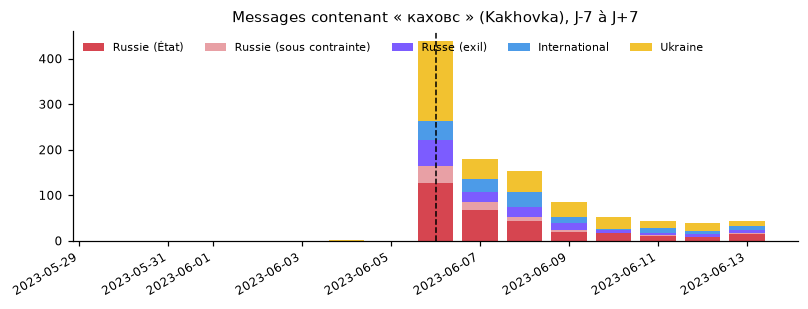

In [8]:
chemin, page = generer_bulletin("2023-06-05", "2023-06-11", "2023-23")
print(f"Bulletin écrit : {chemin.name} ({chemin.stat().st_size / 1e3:.0f} Ko) · ouvre-le dans un navigateur ou imprime-le en PDF")
display(HTML(f'<iframe srcdoc="{escape(page)}" width="100%" height="900" style="border:1px solid #888;background:white"></iframe>'))

## 5. Bulletin n° 2023-25 : semaine de la mutinerie Wagner

Le même générateur, une autre période. C'est tout l'intérêt de l'automatisation : un nouveau bulletin en quelques secondes.

Bulletin écrit : bulletin_2023-25.html


C:\Users\amavi\projects-studio\Extraction de renseignement (NLP) sur sources ouvertes (OSINT)\.venv\Lib\site-packages\IPython\core\display.py:448: UserWarning: Consider using IPython.display.IFrame instead
  warnings.warn("Consider using IPython.display.IFrame instead")



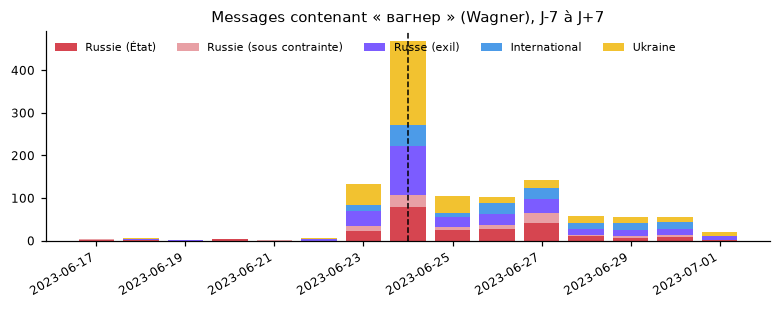

In [9]:
chemin, page = generer_bulletin("2023-06-19", "2023-06-25", "2023-25")
print(f"Bulletin écrit : {chemin.name}")
display(HTML(f'<iframe srcdoc="{escape(page)}" width="100%" height="900" style="border:1px solid #888;background:white"></iframe>'))

## 6. Bilan de l'opération Spirit Digger

Le tableau de bord final, à projeter en conclusion de la démo. Tous les chiffres sont **relus dans les fichiers produits** par les notebooks, aucun n'est recopié à la main.

In [10]:
registre = pd.read_csv(OUTPUTS / "00_registre_sources.csv")
golfe = pd.read_parquet(OUTPUTS / "corpus_golfe.parquet", columns=["doc_id"])
entites = pd.read_parquet(OUTPUTS / "entites_golfe.parquet", columns=["entite"])
noeuds = pd.read_csv(OUTPUTS / "graphe_noeuds.csv")
caches = pd.read_csv(OUTPUTS / "liens_caches.csv")
detecteur = pd.read_csv(OUTPUTS / "detecteur_bilan.csv").iloc[0]
detectes = (validation["score"] >= 30).sum()

tuiles = [
    ("NB 00", "Sources évaluées", f"{len(registre)}", f"{(registre['décision'] == 'ÉCARTÉ').sum()} jeux synthétiques démasqués"),
    ("NB 01", "Documents ingérés", f"{len(telegram) + len(golfe):,}".replace(",", " "), "2 théâtres · 3 langues"),
    ("NB 02", "Entités extraites", f"{len(entites):,}".replace(",", " "), f"{entites['entite'].nunique():,} distinctes".replace(",", " ")),
    ("NB 03", "Événements détectés", f"{detectes}/{len(validation)}", "sans aucun mot-clé fourni"),
    ("NB 04", "Acteurs reliés", f"{len(noeuds)}", f"{len(caches)} liens cachés sourcés"),
    ("NB 05", "Détecteur : test / terrain", f"{detecteur['exactitude_test']:.0%}",
     f"mais {detecteur['faux_positifs_presse_2026']:.0%} de faux positifs en 2026"),
    ("NB 06", "Alertes cotées", f"{len(alertes)}", f"{(alertes['cotation'] == 'B1').sum()} en B1 · 2 bulletins · tasking God's Eye"),
]
cartes = "".join(f"""<div style="background:{FOND};border:1px solid {ACCENT};border-radius:8px;padding:12px 14px">
  <div style="color:{ACCENT};font-size:10px;letter-spacing:2px">{nb}</div>
  <div style="font-size:12px;opacity:.8">{titre}</div>
  <div style="font-size:30px;font-weight:bold;color:{TEXTE}">{valeur}</div>
  <div style="font-size:11px;color:{VEILLE}">{detail}</div></div>""" for nb, titre, valeur, detail in tuiles)
display(HTML(f"""<div style="font-family:monospace;color:{TEXTE}">
<div style="font-size:18px;font-weight:bold;margin-bottom:10px">SPIRIT DIGGER v1.0 · BILAN DE L'OPÉRATION</div>
<div style="display:grid;grid-template-columns:repeat(auto-fill,minmax(210px,1fr));gap:10px">{cartes}</div></div>"""))

## Ce qu'il faut retenir, et la suite

**Ce que démontre Spirit Digger, du bout en bout :**
1. **Évaluer avant d'exploiter** : cotation des sources, jeux truqués et fuites démasqués.
2. **Détecter sans savoir quoi chercher** : 17 des 21 événements majeurs en alerte, sans mot-clé.
3. **Recouper plutôt que croire** : la crédibilité vient de la convergence de camps opposés, pas du style du texte.
4. **Tracer chaque affirmation** : chaque lien et chaque cotation remonte à une phrase source.
5. **Passer à l'action** : un bulletin coté au format OTAN et une demande d'observation satellite pour God's Eye.

> **Phrase de conclusion de la démo :** « Spirit Digger ne remplace pas l'analyste : il lui rend du temps. Il lit 380 000 messages en trois langues, signale l'inattendu, cote ce qu'il trouve comme le fait l'OTAN, montre ses preuves… et demande à God's Eye d'aller voir. Le texte détecte, l'image confirme. »

**Pistes d'évolution :**
- **Traduction et synthèse par un LLM**, pour des bulletins entièrement rédigés en français.
- **Horodatage à la minute**, pour un délai de détection en minutes plutôt qu'en jours.
- **Extraction de relations typées** (« X attaque Y », « X négocie avec Y »), pour un graphe plus riche.
- **Nouvelles sources** : AIS (positions des navires), avis aux navigateurs, pour couvrir l'angle mort maritime du NB 02.
- **Boucle complète avec God's Eye** : que la réponse satellite revienne automatiquement mettre à jour la cotation.